In [1]:
# Bootstrap bands for the response of Mag7 returns to an ASVI8 shock: Table D.1, Figure D.3, Section 4.8.5
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.vector_ar.var_model import VAR

warnings.filterwarnings("ignore")
os.makedirs("output", exist_ok=True)

# Plot style for the thesis figures
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "mathtext.fontset": "dejavuserif", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "legend.frameon": False, "savefig.dpi": 300,
})
blue, orange, green, grey, red = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#8b1a1a"

In [2]:
# Merge the clean files into one monthly data set, December 2015 to December 2025 (121 months)
files = ["spy_clean.csv", "rsp_clean.csv", "voo_clean.csv", "vix_clean.csv", "dgs10_clean.csv",
         "AIStocks_ASVI8_Monthly.csv", "AIStocks_ASVI4_Monthly.csv",
         "mag7_clean.csv", "mag7b_clean.csv", "mag7c_clean.csv"]
df = pd.read_csv(files[0], parse_dates=["date"])
for f in files[1:]:
    df = df.merge(pd.read_csv(f, parse_dates=["date"]), on="date", how="inner")
df = df.sort_values("date").reset_index(drop=True)

# 2021-2025 subsample. December 2020 only serves as the first lag, so the VARs run on Jan 2021 to Dec 2025.
sub = df[df["date"] >= "2020-12-31"].reset_index(drop=True)
print(len(df), "months,", df["date"].min().date(), "to", df["date"].max().date())

cols = ["dlog_vix", "d_dgs10", "ASVI8", "flow_spy", "mag7_ret"]
samples = {"Full sample": df, "2021-2025": sub}

121 months, 2015-12-31 to 2025-12-31


In [3]:
# Bootstrap for VAR impulse responses
# Each bootstrap series is rebuilt recursively from the estimated VAR, y*(t) = c + A y*(t-1) + u*(t),
# starting from the actual first month, with residuals u* drawn with replacement.
# Percentile: the plain percentile bootstrap.
# Bias-corrected: bootstrap-after-bootstrap of Kilian (1998). OLS estimates of VAR coefficients are
# biased toward zero in small samples, so the bias is estimated in a first bootstrap and removed
# before the second one.

def ls_var(Y, p):
    # OLS VAR(p): intercept, lag matrices, residuals and residual covariance (same df correction as statsmodels)
    T, K = Y.shape
    X = np.column_stack([np.ones(T - p)] + [Y[p - j - 1:T - j - 1] for j in range(p)])
    B = np.linalg.lstsq(X, Y[p:], rcond=None)[0]
    U = Y[p:] - X @ B
    sigma = U.T @ U / (T - p - X.shape[1])
    A = [B[1 + j * K:1 + (j + 1) * K].T for j in range(p)]
    return B[0], A, U, sigma


def orth_irf(A, sigma, horizon):
    # Orthogonalized (Cholesky) impulse responses
    K, p = sigma.shape[0], len(A)
    P = np.linalg.cholesky(sigma)
    Phi = [np.eye(K)]
    for h in range(1, horizon + 1):
        Phi.append(sum(A[j] @ Phi[h - 1 - j] for j in range(min(p, h))))
    return np.array([Ph @ P for Ph in Phi])


def simulate(c, A, U, Y_init, T, rng):
    # One bootstrap series of length T
    p, K = len(A), len(c)
    Y = np.empty((T, K))
    Y[:p] = Y_init
    u = U[rng.integers(0, len(U), size=T - p)]
    for t in range(p, T):
        Y[t] = c + sum(A[j] @ Y[t - 1 - j] for j in range(p)) + u[t - p]
    return Y


def max_modulus(A):
    # Largest eigenvalue modulus of the companion matrix
    K, p = A[0].shape[0], len(A)
    C = np.zeros((K * p, K * p))
    C[:K] = np.hstack(A)
    if p > 1:
        C[K:, :-K] = np.eye(K * (p - 1))
    return np.abs(np.linalg.eigvals(C)).max()


def bias_correct(A, bias):
    # Remove the bias, but shrink the correction if it would make the VAR unstable
    delta = 1.0
    A_bc = [a - b for a, b in zip(A, bias)]
    while max_modulus(A_bc) >= 1 and delta > 0:
        delta -= 0.01
        A_bc = [a - delta * b for a, b in zip(A, bias)]
    return A_bc


def bootstrap_bands(data, cols, impulse, response, p=1, horizon=12, reps=2000, bias_reps=1000, seed=42):
    Y = data[cols].to_numpy(dtype=float)
    T = len(Y)
    i, j = cols.index(response), cols.index(impulse)
    rng = np.random.default_rng(seed)

    c, A, U, sigma = ls_var(Y, p)
    U = U - U.mean(axis=0)
    point = orth_irf(A, sigma, horizon)[:, i, j]

    # Asymptotic bands from statsmodels, as in the main text
    se = VAR(Y).fit(p).irf(horizon).stderr(orth=True)[:, i, j]

    # Percentile bootstrap
    draws_pct, A_draws = [], []
    for _ in range(reps):
        _, A_b, _, s_b = ls_var(simulate(c, A, U, Y[:p], T, rng), p)
        A_draws.append(A_b)
        draws_pct.append(orth_irf(A_b, s_b, horizon)[:, i, j])

    # Bias-corrected bootstrap (Kilian, 1998)
    bias = [np.mean([Ad[k] for Ad in A_draws[:bias_reps]], axis=0) - A[k] for k in range(p)]
    A_bc = bias_correct(A, bias)
    c_bc = (np.eye(len(cols)) - sum(A_bc)) @ Y.mean(axis=0)      # keeps the sample mean
    draws_kil = []
    for _ in range(reps):
        _, A_b, _, s_b = ls_var(simulate(c_bc, A_bc, U, Y[:p], T, rng), p)
        draws_kil.append(orth_irf(bias_correct(A_b, bias), s_b, horizon)[:, i, j])

    out = pd.DataFrame({"h": np.arange(horizon + 1), "point": point,
                        "asym_lo": point - 1.959964 * se, "asym_hi": point + 1.959964 * se})
    out["pct_lo"], out["pct_hi"] = np.percentile(np.array(draws_pct), [2.5, 97.5], axis=0)
    out["kilian_lo"], out["kilian_hi"] = np.percentile(np.array(draws_kil), [2.5, 97.5], axis=0)
    for m in ["asym", "pct", "kilian"]:
        out[m + "_excludes_0"] = (out[m + "_lo"] > 0) | (out[m + "_hi"] < 0)
    return out

In [4]:
# 2,000 replications, seed 42 (takes less than a minute)
boot = {name: bootstrap_bands(data, cols, "ASVI8", "mag7_ret") for name, data in samples.items()}
for name, b in boot.items():
    b.to_csv(f"output/bootstrap_irf_{name.replace(' ', '_')}_raw.csv", index=False)
    print(f"{name}: bias-corrected band excludes zero at h = {b['h'][b['kilian_excludes_0']].tolist()}, "
          f"percentile band at h = {b['h'][b['pct_excludes_0']].tolist()}")

Full sample: bias-corrected band excludes zero at h = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12], percentile band at h = []
2021-2025: bias-corrected band excludes zero at h = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12], percentile band at h = []


In [5]:
# Table D.1 (%). "yes" means the 95% band does not contain zero (dagger in the thesis).
rows = []
for name, b in boot.items():
    for _, r in b.iterrows():
        rows.append({"Sample": name, "Months after shock": int(r["h"]), "Point estimate": f"{r['point'] * 100:.3f}",
                     "Asymptotic": f"[{r['asym_lo'] * 100:.3f}, {r['asym_hi'] * 100:.3f}]",
                     "Percentile bootstrap": f"[{r['pct_lo'] * 100:.3f}, {r['pct_hi'] * 100:.3f}]",
                     "Bias-corrected bootstrap": f"[{r['kilian_lo'] * 100:.3f}, {r['kilian_hi'] * 100:.3f}]",
                     "Asymptotic excludes 0": "yes" if r["asym_excludes_0"] else "",
                     "Bias-corrected excludes 0": "yes" if r["kilian_excludes_0"] else ""})
tableD1 = pd.DataFrame(rows)
tableD1.to_csv("output/Table_D1_bootstrap_bands.csv", index=False)
tableD1

,Sample,Months after shock,Point estimate,Asymptotic,Percentile bootstrap,Bias-corrected bootstrap,Asymptotic excludes 0,Bias-corrected excludes 0
0,Full sample,0,1.008,"[-0.081, 2.097]","[-0.232, 2.105]","[-0.260, 2.139]",,
1,Full sample,1,0.802,"[-0.033, 1.637]","[-0.157, 1.529]","[-0.023, 1.648]",,
2,Full sample,2,0.635,"[0.004, 1.267]","[-0.099, 1.139]","[0.037, 1.295]",yes,yes
3,Full sample,3,0.515,"[-0.002, 1.032]","[-0.012, 0.931]","[0.066, 1.121]",,yes
4,Full sample,4,0.403,"[-0.052, 0.858]","[-0.025, 0.768]","[0.040, 0.982]",,yes
5,Full sample,5,0.321,"[-0.069, 0.712]","[-0.016, 0.649]","[0.033, 0.869]",,yes
6,Full sample,6,0.254,"[-0.083, 0.591]","[-0.010, 0.560]","[0.024, 0.776]",,yes
7,Full sample,7,0.202,"[-0.089, 0.492]","[-0.007, 0.476]","[0.017, 0.690]",,yes
8,Full sample,8,0.160,"[-0.089, 0.409]","[-0.004, 0.409]","[0.012, 0.621]",,yes
9,Full sample,9,0.127,"[-0.086, 0.340]","[-0.003, 0.353]","[0.009, 0.557]",,yes


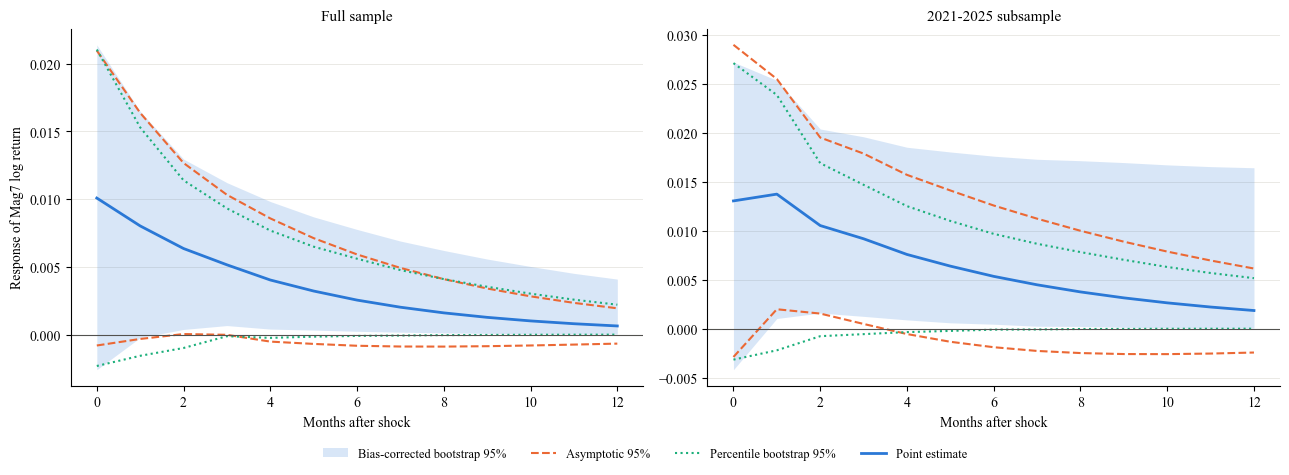

In [6]:
# Figure D.3
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, b) in zip(axes, boot.items()):
    ax.fill_between(b["h"], b["kilian_lo"], b["kilian_hi"], color=blue, alpha=0.18, lw=0,
                    label="Bias-corrected bootstrap 95%")
    ax.plot(b["h"], b["asym_lo"], color=orange, lw=1.5, ls="--", label="Asymptotic 95%")
    ax.plot(b["h"], b["asym_hi"], color=orange, lw=1.5, ls="--")
    ax.plot(b["h"], b["pct_lo"], color=green, lw=1.5, ls=":", label="Percentile bootstrap 95%")
    ax.plot(b["h"], b["pct_hi"], color=green, lw=1.5, ls=":")
    ax.plot(b["h"], b["point"], color=blue, lw=2, label="Point estimate")
    ax.axhline(0, color=grey, lw=0.8)
    ax.set_title("Full sample" if name == "Full sample" else "2021-2025 subsample", fontsize=11)
    ax.set_xlabel("Months after shock")
    ax.set_xticks(range(0, 13, 2))
axes[0].set_ylabel("Response of Mag7 log return")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
fig.savefig("output/Figure_D3_bootstrap_bands.png", dpi=300, bbox_inches="tight")
plt.show()